In [ ]:
from matplotlib import pyplot as plt
from sklearn.preprocessing import normalize
import networkx as nx
import igraph as ig
import leidenalg
import geopandas as gpd
import h3
import numpy as np
import random
seed = 505
random.seed(seed)        # or any integer
np.random.seed(seed)

In [ ]:
# Load data
input_dir = "../data/output_files/retailcen_foursquare_mrc_2_mri_10_mrn_10_mtf_6_merge_n/"
retail_centres = gpd.read_parquet(input_dir + "3_afterfill.parquet")


# Normalize POI vectors to unit length (row-wise L2 norm)
poi_cols = ['Dining and Drinking' , 'Leisure & Travel', 'Community & Health','Commerce']
retail_centres[poi_cols] = retail_centres[poi_cols].fillna(0)
poi_matrix = normalize(retail_centres[poi_cols].values, norm='l2', axis=1)
retail_centres['poi_vec'] = poi_matrix.tolist()

In [ ]:
# Renumber networks by size (largest gets 1, next 2, ...)
retail_centres['network_number'] = retail_centres['network_number'].map(retail_centres['network_number'].value_counts().rank(method='first', ascending=False).astype(int))
network_numbers = retail_centres['network_number'].unique()

153it [00:26,  5.71it/s, resolution_parameter=0.000977]
75it [00:00, 127.94it/s, resolution_parameter=0.0397]
38it [00:00, 340.12it/s, resolution_parameter=0.0777]


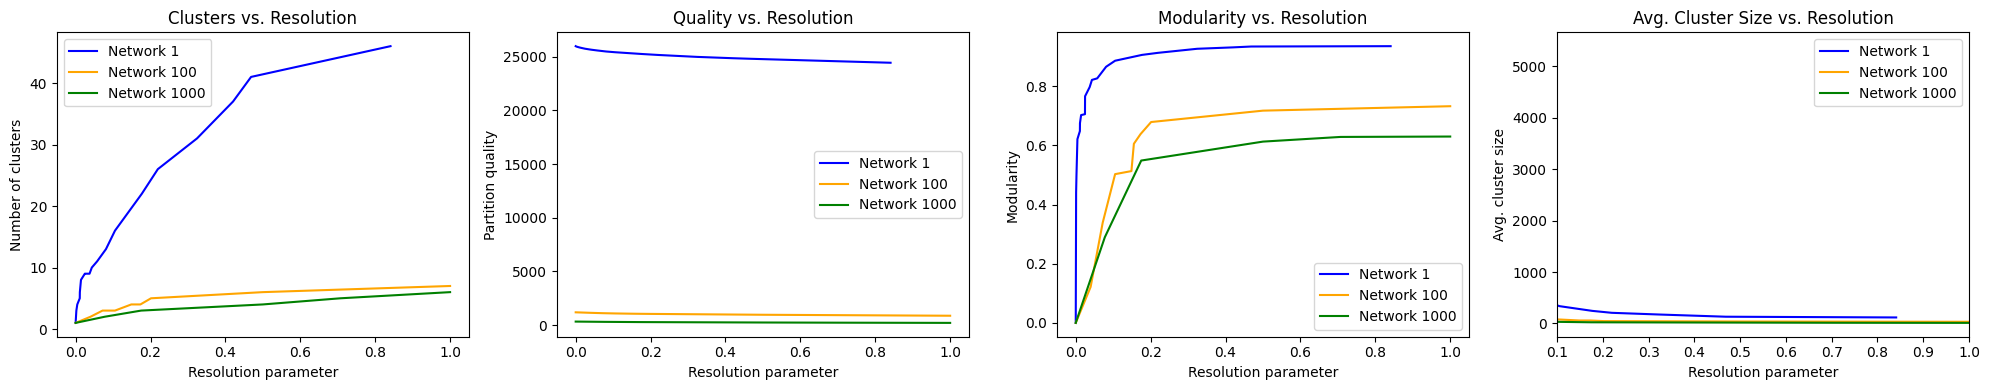

In [63]:

network_numbers = [1, 100, 1000]
colors = ['blue', 'orange', 'green']  # For plotting

plt.figure(figsize=(20, 4))

for i, network_number in enumerate(network_numbers):
    rc = retail_centres[retail_centres['network_number'] == network_number].copy()
    poi_lookup = dict(zip(rc['h3_11'], rc['poi_vec']))
    density_lookup = dict(zip(rc['h3_11'], rc['foursquare_count']))
    h3_set = set(rc['h3_11'])

    G = nx.Graph()
    for h in sorted(h3_set):
        G.add_node(h, density=density_lookup[h])
        neighbors = h3.grid_ring(h, 1)
        for n in sorted(neighbors):
            if n in h3_set and not G.has_edge(h, n):
                sim = np.dot(poi_lookup[h], poi_lookup[n])
                if sim == 0:
                    sim = 0.025
                d1, d2 = density_lookup[h], density_lookup[n]
                weight = d1 + d2 + 1
                if weight > 0:
                    G.add_edge(h, n, weight=weight)

    h3_nodes = list(G.nodes)
    h3_id_map = {h: idx for idx, h in enumerate(h3_nodes)}
    edges = [(h3_id_map[u], h3_id_map[v]) for u, v in G.edges()]
    weights = [G[u][v]['weight'] for u, v in G.edges()]

    if edges:
        G_ig = ig.Graph(n=len(h3_nodes), edges=edges, directed=False)
        G_ig.es['weight'] = weights
        optimiser = leidenalg.Optimiser()
        profile = optimiser.resolution_profile(
            G_ig,
            leidenalg.RBConfigurationVertexPartition,
            resolution_range=(0, 1),
        )

        resolutions = [p.resolution_parameter for p in profile]
        n_clusters = [len(set(p.membership)) for p in profile]
        qualities = [p.quality() for p in profile]
        modularities = [p.modularity for p in profile]
        avg_cluster_sizes = [len(h3_nodes) / nc if nc > 0 else 0 for nc in n_clusters]

        label = f'Network {network_number}'
        c = colors[i]

        plt.subplot(1, 4, 1)
        plt.plot(resolutions, n_clusters, label=label, color=c)

        plt.subplot(1, 4, 2)
        plt.plot(resolutions, qualities, label=label, color=c)

        plt.subplot(1, 4, 3)
        plt.plot(resolutions, modularities, label=label, color=c)

        plt.subplot(1, 4, 4)
        plt.plot(resolutions, avg_cluster_sizes, label=label, color=c)

# Final plot touches
plt.subplot(1, 4, 1)
plt.xlabel("Resolution parameter")
plt.ylabel("Number of clusters")
plt.title("Clusters vs. Resolution")
plt.legend()

plt.subplot(1, 4, 2)
plt.xlabel("Resolution parameter")
plt.ylabel("Partition quality")
plt.title("Quality vs. Resolution")
plt.legend()

plt.subplot(1, 4, 3)
plt.xlabel("Resolution parameter")
plt.ylabel("Modularity")
plt.title("Modularity vs. Resolution")
plt.legend()

plt.subplot(1, 4, 4)
plt.xlabel("Resolution parameter")
plt.xlim(0.1, 1)
plt.ylabel("Avg. cluster size")
plt.title("Avg. Cluster Size vs. Resolution")
plt.legend()

plt.tight_layout()
plt.show()


In [67]:


resolution = 0.15
results = []

for network_number in sorted(retail_centres['network_number'].unique()):
    rc = retail_centres[retail_centres['network_number'] == network_number].copy()
    if rc.empty:
        continue

    poi_lookup = dict(zip(rc['h3_11'], rc['poi_vec']))
    density_lookup = dict(zip(rc['h3_11'], rc['foursquare_count']))
    h3_set = set(rc['h3_11'])

    G = nx.Graph()
    for h in sorted(h3_set):
        G.add_node(h, density=density_lookup[h])
        neighbors = h3.grid_ring(h, 1)
        for n in sorted(neighbors):
            if n in h3_set and not G.has_edge(h, n):
                sim = np.dot(poi_lookup[h], poi_lookup[n])
                if sim == 0:
                    sim = 0.025
                d1, d2 = density_lookup[h], density_lookup[n]
                weight = d1 + d2 + 1
                if weight > 0:
                    G.add_edge(h, n, weight=weight)

    h3_nodes = list(G.nodes)
    h3_id_map = {h: idx for idx, h in enumerate(h3_nodes)}
    edges = [(h3_id_map[u], h3_id_map[v]) for u, v in G.edges()]
    weights = [G[u][v]['weight'] for u, v in G.edges()]

    if edges:
        G_ig = ig.Graph(n=len(h3_nodes), edges=edges, directed=False)
        G_ig.es['weight'] = weights

        partition = leidenalg.find_partition(
            G_ig,
            leidenalg.RBConfigurationVertexPartition,
            resolution_parameter=resolution,
            weights=weights,
        )

        n_clusters = len(set(partition.membership))
        avg_cluster_size = len(h3_nodes) / n_clusters if n_clusters > 0 else 0

        results.append({
            'network_number': network_number,
            'num_nodes': len(h3_nodes),
            'num_clusters': n_clusters,
            'avg_cluster_size': avg_cluster_size
        })

# Convert to DataFrame (optional, for analysis)
import pandas as pd
results_df = pd.DataFrame(results)
print(results_df.head())

# Optionally, get summary statistics
print("\nOverall average cluster size:", results_df['avg_cluster_size'].mean())



   network_number  num_nodes  num_clusters  avg_cluster_size
0               1       5387            21        256.523810
1               2       1084            13         83.384615
2               3        891             9         99.000000
3               4        828             8        103.500000
4               5        781             5        156.200000

Overall average cluster size: 12.807782034578606


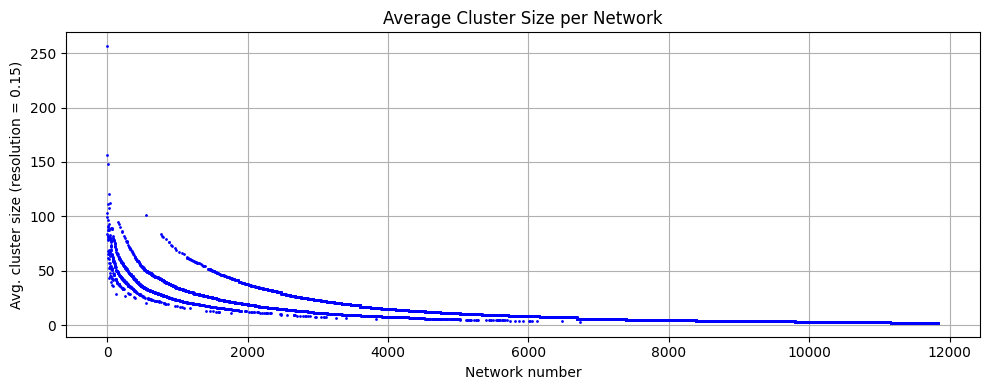

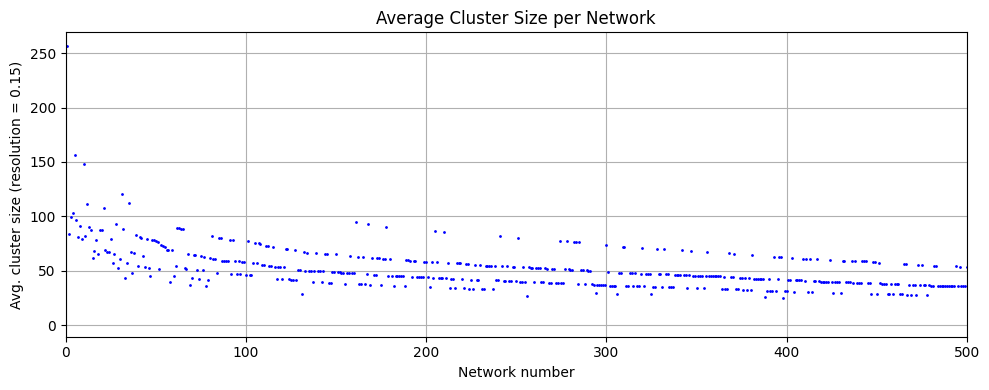

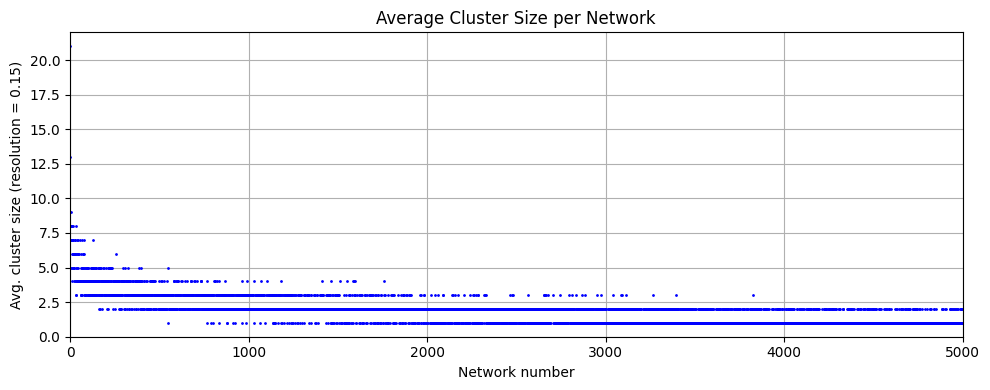

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(results_df['network_number'], results_df['avg_cluster_size'], marker='o',ls="", markersize=1, color='blue')
plt.xlabel("Network number")
plt.ylabel("Avg. cluster size (resolution = 0.15)")
plt.title("Average Cluster Size per Network")
plt.grid(True)
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(results_df['network_number'], results_df['avg_cluster_size'], marker='o',ls="", markersize=1, color='blue')
plt.xlabel("Network number")
plt.ylabel("Avg. cluster size (resolution = 0.15)")
plt.title("Average Cluster Size per Network")
plt.grid(True)
plt.xlim(0, 500)
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(results_df['network_number'], results_df['num_clusters'], marker='o',ls="", markersize=1, color='blue')
plt.xlabel("Network number")
plt.ylabel("Avg. cluster size (resolution = 0.15)")
plt.title("Average Cluster Size per Network")
plt.grid(True)
plt.xlim(0, 5000)
plt.tight_layout()
plt.show()


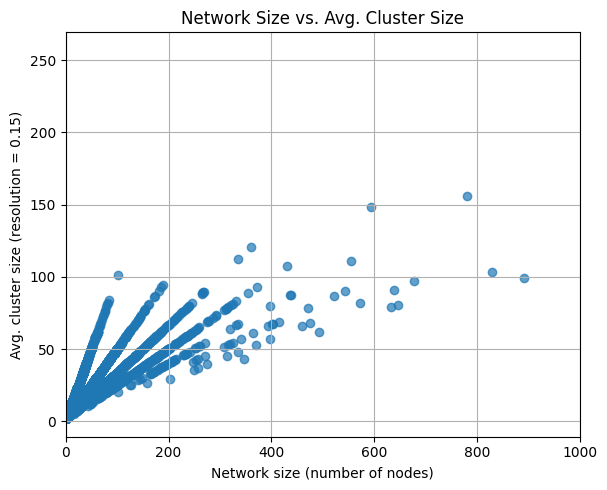

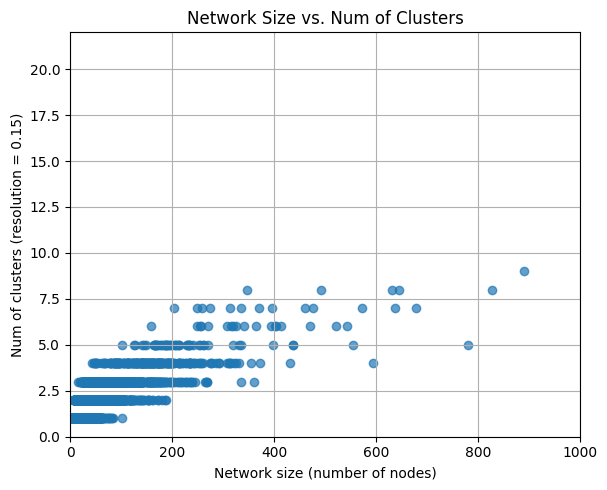

In [83]:
plt.figure(figsize=(6, 5))
plt.scatter(results_df['num_nodes'], results_df['avg_cluster_size'], alpha=0.7)
plt.xlabel("Network size (number of nodes)")
plt.ylabel("Avg. cluster size (resolution = 0.15)")
plt.title("Network Size vs. Avg. Cluster Size")
plt.grid(True)
plt.tight_layout()
plt.xlim(0, 1000)
plt.show()


plt.figure(figsize=(6, 5))
plt.scatter(results_df['num_nodes'], results_df['num_clusters'], alpha=0.7)
plt.xlabel("Network size (number of nodes)")
plt.ylabel("Num of clusters (resolution = 0.15)")
plt.title("Network Size vs. Num of Clusters")
plt.grid(True)
plt.tight_layout()
plt.xlim(0, 1000)
#plot(x=y)
plt.show()


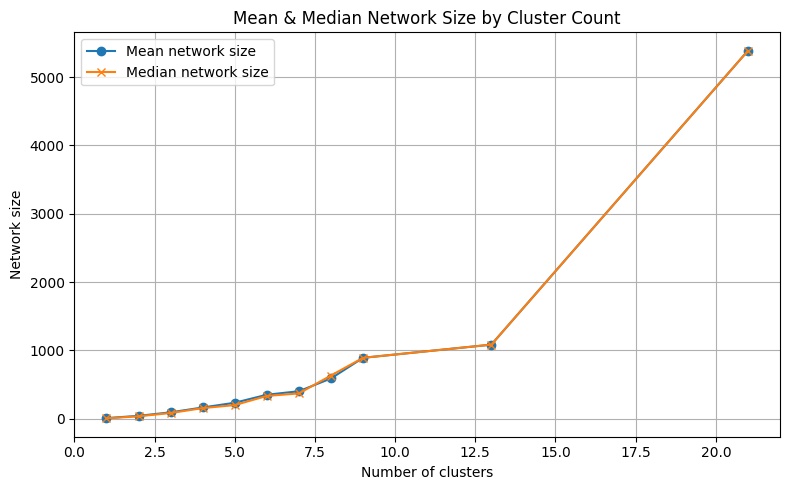

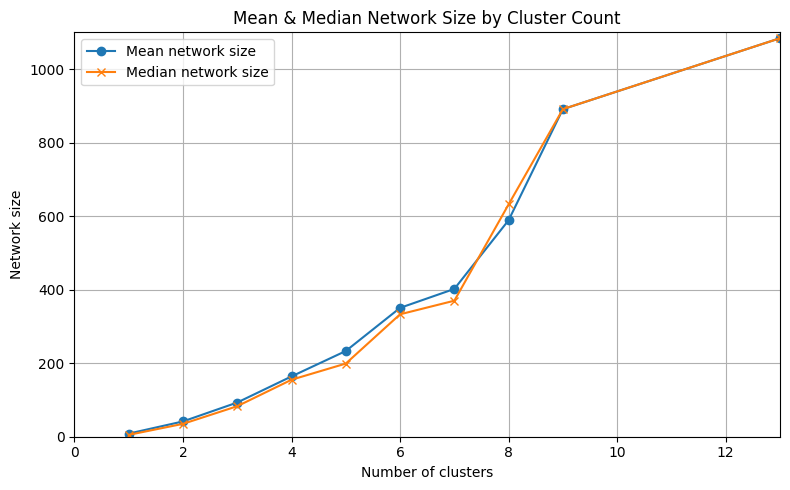

In [86]:
# Group by number of clusters and compute mean and median network size
grouped = results_df.groupby('num_clusters')['num_nodes'].agg(['mean', 'median']).reset_index()

# Plot
plt.figure(figsize=(8, 5))
plt.plot(grouped['num_clusters'], grouped['mean'], label='Mean network size', marker='o')
plt.plot(grouped['num_clusters'], grouped['median'], label='Median network size', marker='x')
plt.xlabel("Number of clusters")
plt.ylabel("Network size")
plt.title("Mean & Median Network Size by Cluster Count")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Group by number of clusters and compute mean and median network size
grouped = results_df.groupby('num_clusters')['num_nodes'].agg(['mean', 'median']).reset_index()

# Plot
plt.figure(figsize=(8, 5))
plt.plot(grouped['num_clusters'], grouped['mean'], label='Mean network size', marker='o')
plt.plot(grouped['num_clusters'], grouped['median'], label='Median network size', marker='x')
plt.xlabel("Number of clusters")
plt.ylabel("Network size")
plt.title("Mean & Median Network Size by Cluster Count")
plt.legend()
plt.grid(True)
plt.xlim(0, 13)
plt.ylim(0, 1100)
plt.tight_layout()
plt.show()




247it [00:39,  6.23it/s, resolution_parameter=0.000977]
99it [00:01, 55.77it/s, resolution_parameter=0.0326]
93it [00:00, 140.60it/s, resolution_parameter=0.0397]
58it [00:00, 430.52it/s, resolution_parameter=0.0777]


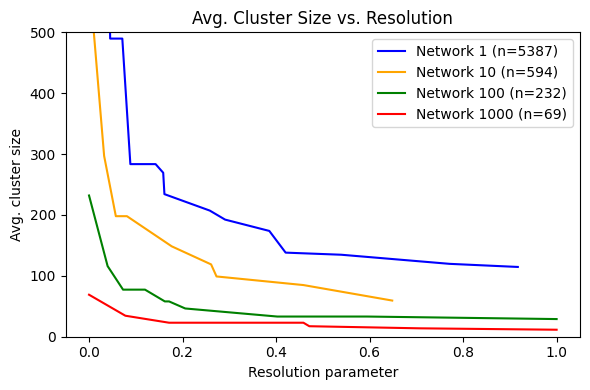

In [66]:


network_numbers = [1, 10, 100, 1000]
colors = ['blue', 'orange', 'green', 'red']  # For plotting

plt.figure(figsize=(6, 4))

for i, network_number in enumerate(network_numbers):
    rc = retail_centres[retail_centres['network_number'] == network_number].copy()
    poi_lookup = dict(zip(rc['h3_11'], rc['poi_vec']))
    density_lookup = dict(zip(rc['h3_11'], rc['foursquare_count']))
    h3_set = set(rc['h3_11'])

    G = nx.Graph()
    for h in sorted(h3_set):
        G.add_node(h, density=density_lookup[h])
        neighbors = h3.grid_ring(h, 1)
        for n in sorted(neighbors):
            if n in h3_set and not G.has_edge(h, n):
                sim = np.dot(poi_lookup[h], poi_lookup[n])
                if sim == 0:
                    sim = 0.025
                d1, d2 = density_lookup[h], density_lookup[n]
                weight = d1 + d2 + 1
                if weight > 0:
                    G.add_edge(h, n, weight=weight)

    h3_nodes = list(G.nodes)
    h3_id_map = {h: idx for idx, h in enumerate(h3_nodes)}
    edges = [(h3_id_map[u], h3_id_map[v]) for u, v in G.edges()]
    weights = [G[u][v]['weight'] for u, v in G.edges()]

    if edges:
        G_ig = ig.Graph(n=len(h3_nodes), edges=edges, directed=False)
        G_ig.es['weight'] = weights
        optimiser = leidenalg.Optimiser()
        profile = optimiser.resolution_profile(
            G_ig,
            leidenalg.RBConfigurationVertexPartition,
            resolution_range=(0, 1),
        )

        resolutions = [p.resolution_parameter for p in profile]
        n_clusters = [len(set(p.membership)) for p in profile]
        avg_cluster_sizes = [len(h3_nodes) / nc if nc > 0 else 0 for nc in n_clusters]

        label = f'Network {network_number} (n={len(h3_nodes)})'

        plt.plot(resolutions, avg_cluster_sizes, label=label, color=colors[i])

plt.xlabel("Resolution parameter")
plt.ylabel("Avg. cluster size")
plt.title("Avg. Cluster Size vs. Resolution")
plt.ylim(0, 500)
plt.legend()
plt.tight_layout()
plt.show()


196it [00:31,  6.31it/s, resolution_parameter=0.000977]


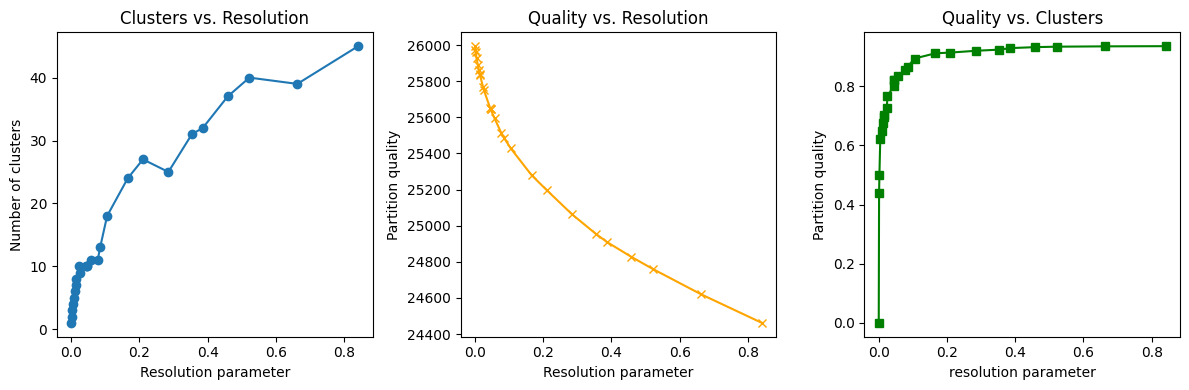

In [ ]:
optimiser = leidenalg.Optimiser()
profile = optimiser.resolution_profile(
    G_ig,
    leidenalg.RBConfigurationVertexPartition,
    resolution_range=(0, 1),
)

# Extract values from profile
resolutions = [p.resolution_parameter for p in profile]
n_clusters = [len(set(p.membership)) for p in profile]
qualities = [p.quality() for p in profile]
modularities = [p.modularity for p in profile]
# Print the results

# Plot all relevant parameters
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(resolutions, n_clusters, marker='o')
plt.xlabel("Resolution parameter")
plt.ylabel("Number of clusters")
plt.title("Clusters vs. Resolution")

plt.subplot(1, 3, 2)
plt.plot(resolutions, qualities, marker='x', color='orange')
plt.xlabel("Resolution parameter")
plt.ylabel("Partition quality")
plt.title("Quality vs. Resolution")

plt.subplot(1, 3, 3)
plt.plot(resolutions, modularities, marker='s', color='green')
plt.xlabel("resolution parameter")
plt.ylabel("Partition quality")
plt.title("Quality vs. Clusters")

plt.tight_layout()
plt.show()


